# BÁO CÁO DỰ ÁN PHÂN TÍCH DỮ LIỆU
## CHUYÊN ĐỀ: PHÂN TÍCH MỐI QUAN HỆ GIỮA CÁC CHỈ TIÊU HÓA LÝ VÀ CHẤT LƯỢNG CẢM QUAN CỦA RƯỢU VANG ĐỎ (RED WINE QUALITY)
- **Nguồn dữ liệu:** UCI Machine Learning Repository (Nghiên cứu của P. Cortez, A. Cerdeira, F. Almeida, T. Matos và J. Reis, 2009 - Đại học Minho và CVRVV, Bồ Đào Nha).
- **Đặc trưng biến mục tiêu:** Điểm chất lượng cảm quan (`quality`), được xác định bằng trung vị (median) của ít nhất 3 lần đánh giá từ các chuyên gia nếm thử, trên thang điểm 0–10.
- **Cấu trúc thực hiện:**
  - **Giai đoạn 1:** Thu thập, kiểm tra cấu trúc, rà soát kiểu dữ liệu và tỷ lệ khuyết thiếu (Missing values).
  - **Giai đoạn 2:** Tiền xử lý dữ liệu: Khử trùng lặp (Deduplication) kèm phân tích độ nhạy (Sensitivity analysis), trực quan hóa phân phối biến mục tiêu (Figure 3), định lượng ngoại lệ IQR trên toàn bộ 11 biến (Figure 1), phân tích tỷ lệ ảnh hưởng của outlier (Union of outliers), áp dụng kỹ thuật Winsorization và so sánh chuẩn hóa RobustScaler vs StandardScaler (Figure 2).
  - **Giai đoạn 3:** Phân tích thống kê & Trực quan hóa: So sánh Pearson trước/sau tiền xử lý trên toàn bộ 11 biến, kiểm định đối chiếu Spearman rank correlation 11 biến, kiểm định Welch's t-test, kiểm tra phương sai Levene 6 nhóm, Welch ANOVA (sử dụng survival function sf), kiểm định hậu kiểm Games-Howell (thay cho Tukey HSD), phân tích Heatmap (Centered VIF, Figure 4), Violin-Boxplot (Figure 5), Scatter plot tham chiếu với custom handles (Figure 6) và so sánh median đặc trưng RobustScaled (Figure 7 kèm bảng chênh lệch delta).
  - **Giai đoạn 4:** Đánh giá tác động chuyên môn và quy trình kiểm soát, đề xuất giải pháp ứng dụng học máy với Pipeline chống rò rỉ dữ liệu, chỉ rõ các giới hạn dữ liệu và tài liệu tham khảo.


In [1]:
# 1. Cài đặt và nạp các thư viện phân tích dữ liệu cần thiết
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pingouin as pg
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import RobustScaler, StandardScaler
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore')

# Thiết lập phong cách trực quan hóa
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
print("Thư viện đã được nạp thành công (bao gồm pingouin)!")

Thư viện đã được nạp thành công (bao gồm pingouin)!


---
# GIAI ĐOẠN 1: THU THẬP VÀ ĐÁNH GIÁ DỮ LIỆU BAN ĐẦU
### 1.1. Đọc dữ liệu gốc và kiểm tra kích thước
Nguồn dữ liệu: Tập dữ liệu Red Wine Quality từ UCI Machine Learning Repository (Cortez et al., 2009).

In [2]:
# Đọc dữ liệu gốc
df_raw = pd.read_csv('winequality-red.csv')

print(f"Kích thước tập dữ liệu gốc (Shape): {df_raw.shape[0]} dòng, {df_raw.shape[1]} thuộc tính.")
df_raw.head()

Kích thước tập dữ liệu gốc (Shape): 1599 dòng, 12 thuộc tính.


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### 1.2. Rà soát cấu trúc, kiểu dữ liệu và tỷ lệ khuyết thiếu (Missing Values)
- **Định nghĩa biến mục tiêu:** Điểm chất lượng cảm quan (`quality`), được xác định bằng trung vị (median) của ít nhất 3 lần đánh giá từ các chuyên gia nếm thử, trên thang điểm 0–10.

In [3]:
audit_table = pd.DataFrame({
    'Kiểu Dtype': df_raw.dtypes,
    'Số bản ghi hợp lệ': df_raw.count(),
    'Số lượng thiếu (NaN)': df_raw.isnull().sum(),
    'Tỷ lệ thiếu (%)': (df_raw.isnull().sum() / len(df_raw)) * 100,
    'Số giá trị duy nhất (Unique)': df_raw.nunique()
})
audit_table

,Kiểu Dtype,Số bản ghi hợp lệ,Số lượng thiếu (NaN),Tỷ lệ thiếu (%),Số giá trị duy nhất (Unique)
fixed acidity,float64,1599,0,0.0,96
volatile acidity,float64,1599,0,0.0,143
citric acid,float64,1599,0,0.0,80
residual sugar,float64,1599,0,0.0,91
chlorides,float64,1599,0,0.0,153
free sulfur dioxide,float64,1599,0,0.0,60
total sulfur dioxide,float64,1599,0,0.0,144
density,float64,1599,0,0.0,436
pH,float64,1599,0,0.0,89
sulphates,float64,1599,0,0.0,96


### 1.3. Thống kê mô tả tổng quan trên tập dữ liệu gốc (1,599 mẫu)

In [4]:
summary_desc_raw = df_raw.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary_desc_raw['IQR'] = summary_desc_raw['75%'] - summary_desc_raw['25%']
summary_desc_raw

,count,mean,std,min,25%,50%,75%,max,IQR
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000,2.100000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000,0.250000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000,0.330000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000,0.700000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100,0.020000
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000,14.000000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000,40.000000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369,0.002235
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000,0.190000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000,0.180000


---
# GIAI ĐOẠN 2: TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU

### 2.1. Phát hiện và xử lý dữ liệu trùng lặp (Deduplication) kèm Phân tích độ nhạy
- **Thực trạng dữ liệu:** Đối chiếu toàn bộ 12 thuộc tính, phát hiện 240 dòng trùng lặp hoàn toàn (15.01%).
- **Thừa nhận hạn chế:** Do tập dữ liệu UCI không cung cấp mã định danh mẫu rượu (Sample ID), ta không thể khẳng định chắc chắn 240 dòng này là lỗi nhập liệu hay là các mẫu rượu độc lập ngẫu nhiên có cùng các chỉ tiêu đo lường.
- **Quyết định kỹ thuật:** Nhóm tiến hành loại bỏ 240 bản ghi lặp nhằm mục đích kỹ thuật là ngăn ngừa nguy cơ **Data Leakage** (rò rỉ dữ liệu cùng bản ghi vào cả tập train và test khi phân chia mô hình).
- **Phân tích độ nhạy (Sensitivity Analysis):** Để kiểm tra xem việc loại bỏ 240 dòng này có làm thay đổi đáng kể các hệ số tương quan của 7 biến được khảo sát hay không, nhóm đối chiếu trực tiếp tương quan Pearson trên tập 1,599 mẫu gốc và tập 1,359 mẫu sau khử trùng lặp.

In [5]:
n_dup = df_raw.duplicated().sum()
pct_dup = (n_dup / len(df_raw)) * 100
print(f"Số lượng bản ghi trùng lặp: {n_dup} dòng ({pct_dup:.2f}% trên 1,599 mẫu gốc)")

# Lưu bản sao dữ liệu sạch gốc sau deduplication
df_clean_original = df_raw.drop_duplicates(keep='first').copy()
print(f"Kích thước sau khử trùng lặp: {df_clean_original.shape[0]} dòng, {df_clean_original.shape[1]} thuộc tính.")

# Phân tích độ nhạy: So sánh Pearson giữa 1,599 mẫu gốc và 1,359 mẫu sau deduplication (7 biến)
sens_features = ['alcohol', 'volatile acidity', 'sulphates', 'citric acid', 'residual sugar', 'chlorides', 'total sulfur dioxide']
sens_records = []
for col in sens_features:
    r_raw, p_raw = stats.pearsonr(df_raw[col], df_raw['quality'])
    r_dedup, p_dedup = stats.pearsonr(df_clean_original[col], df_clean_original['quality'])
    sens_records.append({
        'Thuộc tính': col,
        'Pearson r (1,599 mẫu gốc)': round(r_raw, 6),
        'Pearson r (1,359 mẫu sau dedup)': round(r_dedup, 6),
        'Chênh lệch delta r': round(r_dedup - r_raw, 6)
    })
print("\n--- BẢNG PHÂN TÍCH ĐỘ NHẠY CỦA BƯỚC KHỬ TRÙNG LẶP (DEDUPLICATION) ---")
display(pd.DataFrame(sens_records))

Số lượng bản ghi trùng lặp: 240 dòng (15.01% trên 1,599 mẫu gốc)
Kích thước sau khử trùng lặp: 1359 dòng, 12 thuộc tính.

--- BẢNG PHÂN TÍCH ĐỘ NHẠY CỦA BƯỚC KHỬ TRÙNG LẶP (DEDUPLICATION) ---


,Thuộc tính,"Pearson r (1,599 mẫu gốc)","Pearson r (1,359 mẫu sau dedup)",Chênh lệch delta r
0,alcohol,0.476166,0.480343,0.004177
1,volatile acidity,-0.390558,-0.395214,-0.004656
2,sulphates,0.251397,0.248835,-0.002562
3,citric acid,0.226373,0.228057,0.001685
4,residual sugar,0.013732,0.013640,-0.000091
5,chlorides,-0.128907,-0.130988,-0.002082
6,total sulfur dioxide,-0.185100,-0.177855,0.007245


### 2.2. Phân phối biến mục tiêu và nhãn nhị phân trên tập dữ liệu sau Deduplication (Figure 3)
- Đồng bộ quần thể mẫu: Toàn bộ phân phối bên dưới được vẽ trên tập **1,359 mẫu duy nhất** sau khử trùng lặp (`df_clean_original`).
- Định nghĩa biến mục tiêu: Điểm chất lượng cảm quan (`quality`), được xác định bằng trung vị (median) của ít nhất 3 lần đánh giá từ các chuyên gia nếm thử, trên thang điểm 0–10.

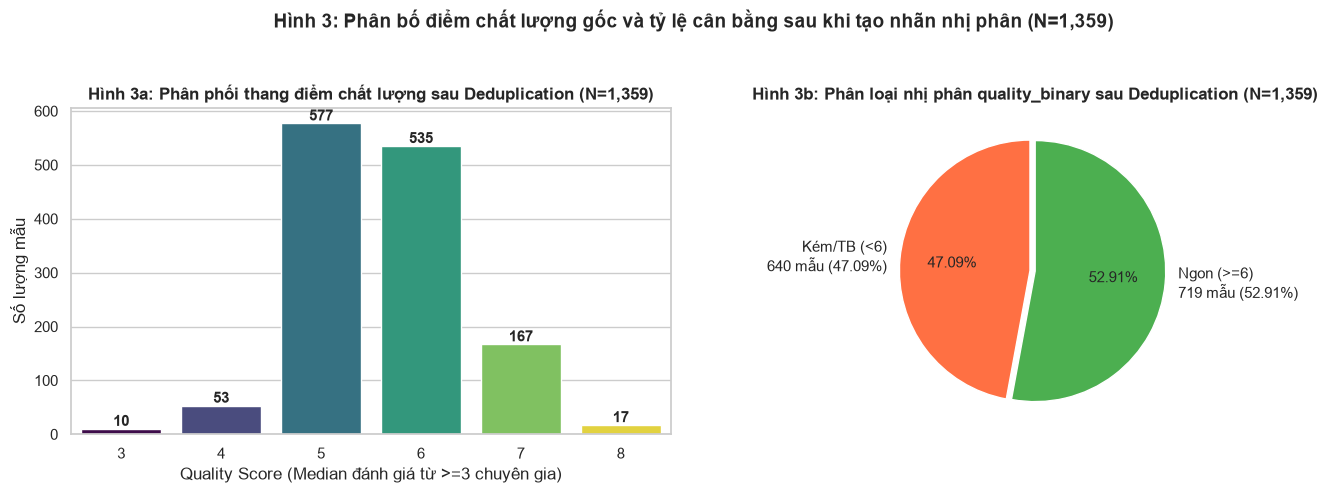

In [6]:
# Tạo biến nhị phân quality_binary (<6 vs >=6)
df_clean_original['quality_binary'] = (df_clean_original['quality'] >= 6).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Phân phối 6 mức điểm
sns.countplot(x='quality', hue='quality', data=df_clean_original, palette='viridis', ax=axes[0], legend=False)
axes[0].set_title('Hình 3a: Phân phối thang điểm chất lượng sau Deduplication (N=1,359)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Quality Score (Median đánh giá từ >=3 chuyên gia)')
axes[0].set_ylabel('Số lượng mẫu')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

# 2. Phân phối nhãn nhị phân
bin_counts = df_clean_original['quality_binary'].value_counts().sort_index()
labels = [f'Kém/TB (<6)\n{bin_counts[0]} mẫu ({bin_counts[0]/len(df_clean_original)*100:.2f}%)',
          f'Ngon (>=6)\n{bin_counts[1]} mẫu ({bin_counts[1]/len(df_clean_original)*100:.2f}%)']
axes[1].pie([bin_counts[0], bin_counts[1]], labels=labels, autopct='%1.2f%%', colors=['#FF7043', '#4CAF50'], startangle=90, explode=(0.04, 0))
axes[1].set_title('Hình 3b: Phân loại nhị phân quality_binary sau Deduplication (N=1,359)', fontsize=12, fontweight='bold')

fig.suptitle('Hình 3: Phân bố điểm chất lượng gốc và tỷ lệ cân bằng sau khi tạo nhãn nhị phân (N=1,359)', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### 2.3. Nhận diện và Định lượng Ngoại lệ (Outliers) bằng phương pháp IQR trên toàn bộ 11 biến đầu vào (Figure 1)
- **Lưu ý phương pháp:** Bảng và biểu đồ bên dưới bao gồm **đầy đủ 11 biến hóa lý đầu vào** trên 1,359 mẫu trước khi Winsorization. Biến mục tiêu `quality` là thang đo thứ bậc cảm quan (ordinal scale từ 3 đến 8); các điểm cực biên 3 và 8 là đánh giá cảm quan thực tế của hội đồng chuyên gia, **không phải là dữ liệu lỗi hay ngoại lệ cần loại bỏ**.

In [7]:
input_features = [col for col in df_clean_original.columns if col not in ['quality', 'quality_binary']]

outlier_summary = []
for col in input_features:
    q1 = df_clean_original[col].quantile(0.25)
    q3 = df_clean_original[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    cnt = ((df_clean_original[col] < low) | (df_clean_original[col] > high)).sum()
    pct = (cnt / len(df_clean_original)) * 100
    outlier_summary.append({
        'Thuộc tính': col,
        'Q1': round(q1, 4),
        'Median': round(df_clean_original[col].median(), 4),
        'Q3': round(q3, 4),
        'IQR': round(iqr, 4),
        'Ngưỡng dưới': round(low, 4),
        'Ngưỡng trên': round(high, 4),
        'Số Outlier': cnt,
        'Tỷ lệ Outlier (%)': round(pct, 2)
    })

iqr_df = pd.DataFrame(outlier_summary)
display(iqr_df)

,Thuộc tính,Q1,Median,Q3,IQR,Ngưỡng dưới,Ngưỡng trên,Số Outlier,Tỷ lệ Outlier (%)
0,fixed acidity,7.1000,7.9000,9.2000,2.1000,3.9500,12.3500,41,3.02
1,volatile acidity,0.3900,0.5200,0.6400,0.2500,0.0150,1.0150,19,1.40
2,citric acid,0.0900,0.2600,0.4300,0.3400,-0.4200,0.9400,1,0.07
3,residual sugar,1.9000,2.2000,2.6000,0.7000,0.8500,3.6500,126,9.27
4,chlorides,0.0700,0.0790,0.0910,0.0210,0.0385,0.1225,87,6.40
5,free sulfur dioxide,7.0000,14.0000,21.0000,14.0000,-14.0000,42.0000,26,1.91
6,total sulfur dioxide,22.0000,38.0000,63.0000,41.0000,-39.5000,124.5000,45,3.31
7,density,0.9956,0.9967,0.9978,0.0022,0.9923,1.0012,35,2.58
8,pH,3.2100,3.3100,3.4000,0.1900,2.9250,3.6850,28,2.06
9,sulphates,0.5500,0.6200,0.7300,0.1800,0.2800,1.0000,55,4.05


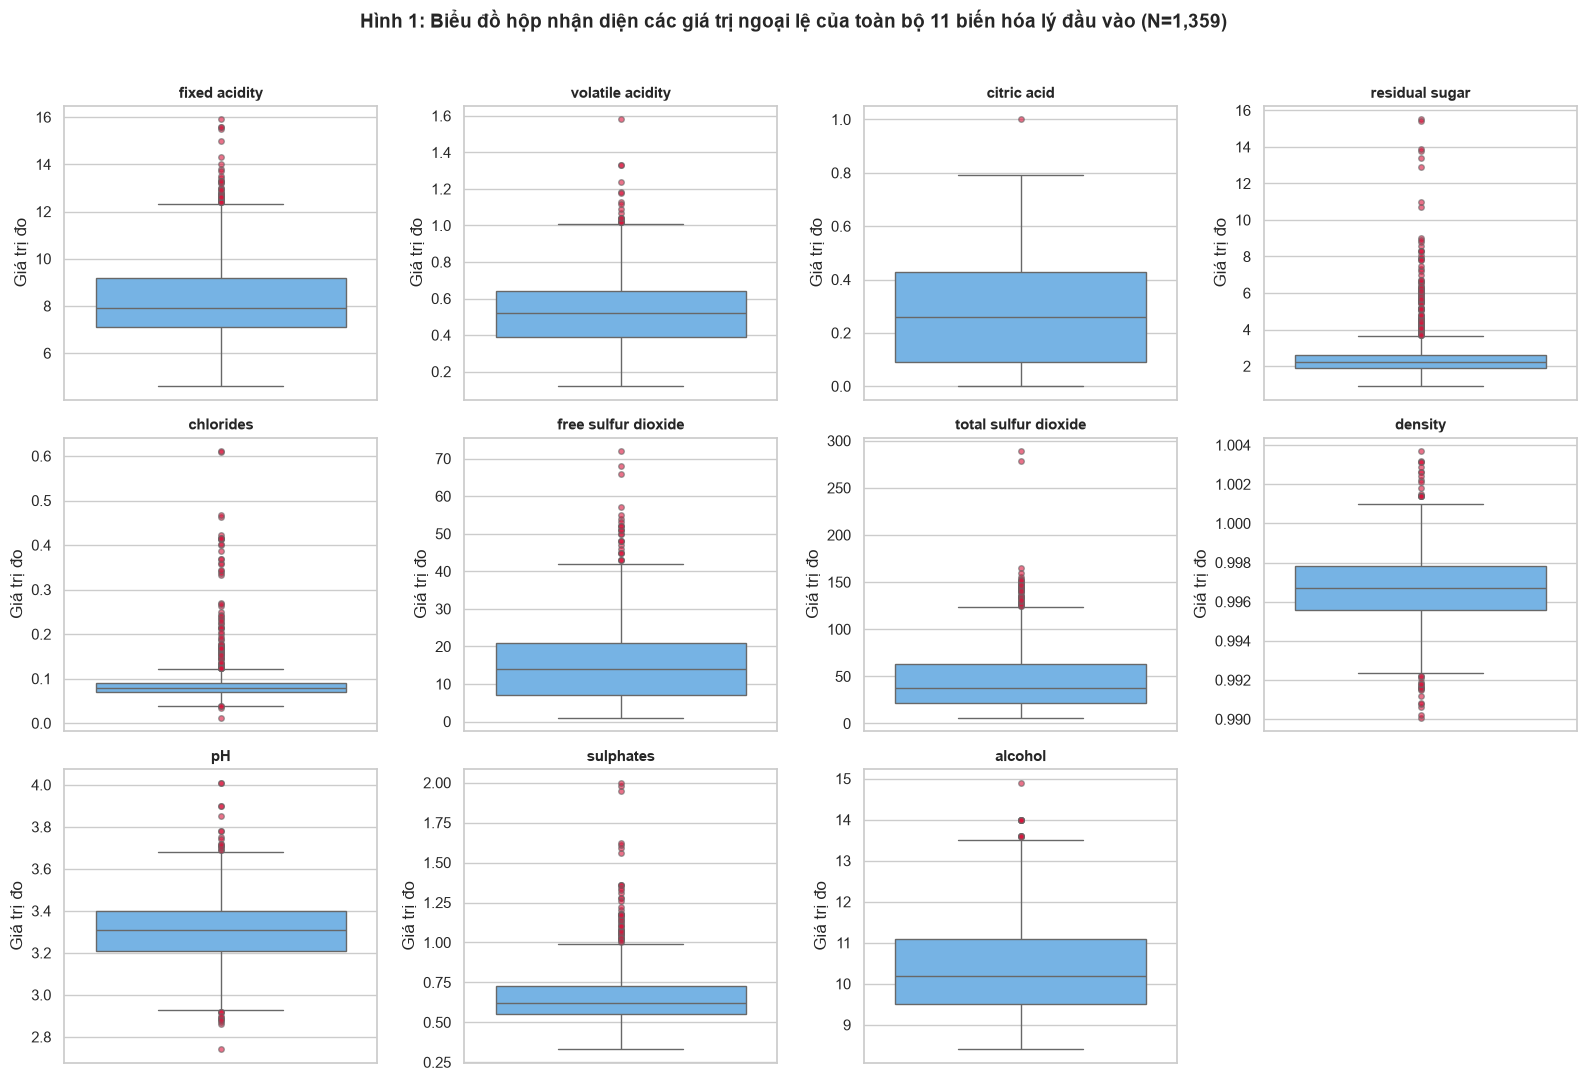

In [8]:
# Vẽ Figure 1: Boxplots cho toàn bộ 11 biến hóa lý đầu vào trên df_clean_original
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for idx, col in enumerate(input_features):
    sns.boxplot(y=df_clean_original[col], ax=axes[idx], color='#64B5F6',
                flierprops=dict(marker='o', markersize=4, markerfacecolor='crimson', alpha=0.6))
    axes[idx].set_title(col, fontsize=11, fontweight='bold')
    axes[idx].set_ylabel('Giá trị đo')

axes[11].axis('off')
fig.suptitle('Hình 1: Biểu đồ hộp nhận diện các giá trị ngoại lệ của toàn bộ 11 biến hóa lý đầu vào (N=1,359)', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 2.4. Phân tích tập hợp dòng chứa Outlier (Union of Outliers), Winsorization và So sánh Scaling (Figure 2)
- **Tập hợp dòng chứa ngoại lệ:** Do một mẫu rượu có thể là ngoại lệ ở nhiều biến đồng thời, ta tính `outlier_mask.any(axis=1)` để xác định chính xác số mẫu bị loại nếu dùng phương án Drop outliers (ghi nhận 340 / 1,359 mẫu, chiếm 25.02%).
- **Bản chất của RobustScaler:** RobustScaler giúp giảm ảnh hưởng của các giá trị cực đoan đến tham số chuẩn hóa (dựa trên Median và IQR), nhưng **không trực tiếp loại bỏ các giá trị ngoại lệ hoặc khắc phục độ lệch phân phối (skewness)**.
- **Phân định phạm vi dữ liệu:** *Phần lớn các phân tích suy luận thống kê (Pearson, Spearman, Welch's t-test và Welch ANOVA) cùng các biểu đồ Figure 4–7 sử dụng dữ liệu sau Winsorization. Riêng Figure 1–3 được xây dựng trên dữ liệu sau khử trùng lặp nhưng chưa Winsorization nhằm phản ánh đặc điểm phân phối ban đầu và minh họa các bước tiền xử lý.*

Số dòng có ít nhất một thuộc tính ngoại lệ: 340 / 1359 (25.02%)


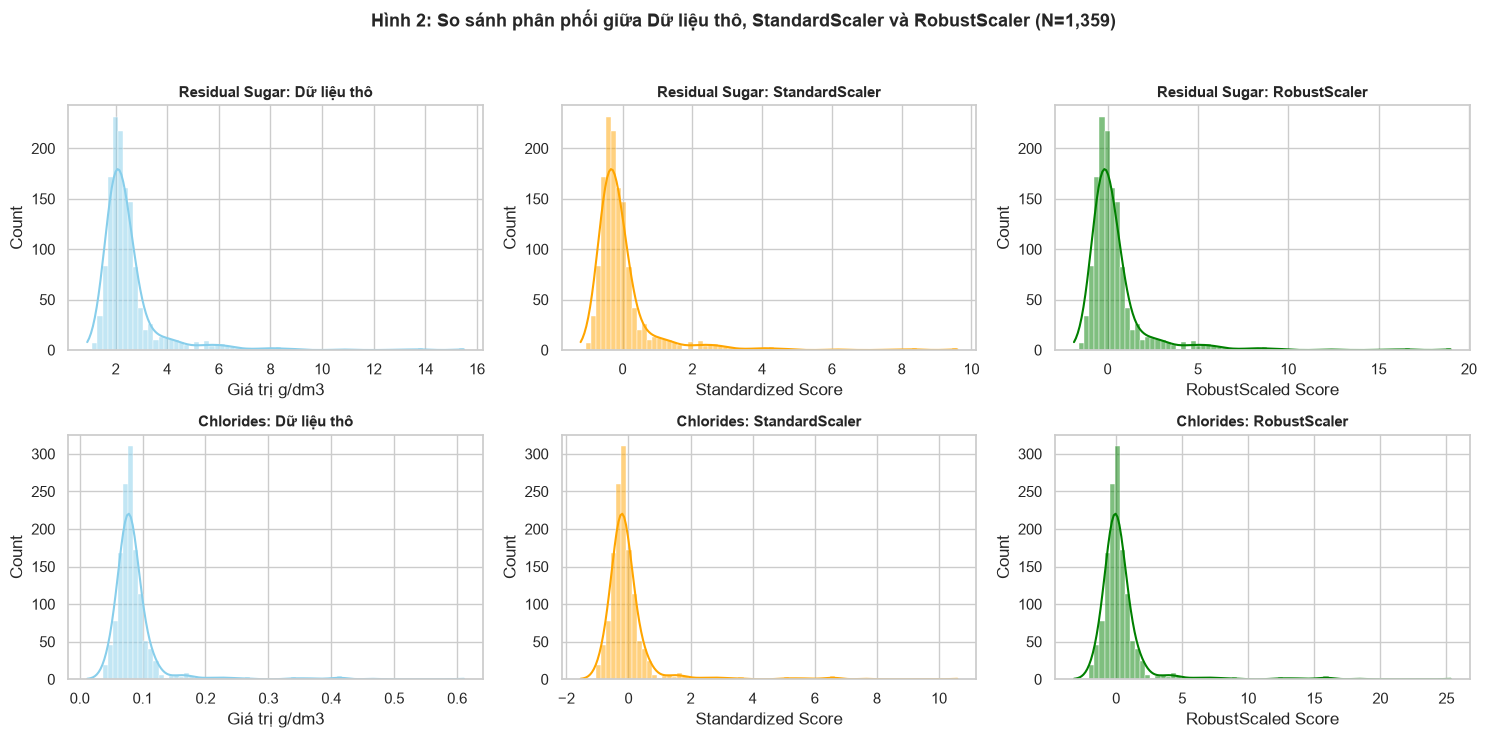

Đã lưu tập dữ liệu sạch hoàn chỉnh 'winequality-red-cleaned.csv'. Shape: (1359, 24)


In [9]:
# 1. Tính chính xác số dòng có ít nhất một thuộc tính ngoại lệ
outlier_mask = pd.DataFrame(index=df_clean_original.index)
for col in input_features:
    q1 = df_clean_original[col].quantile(0.25)
    q3 = df_clean_original[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_mask[col] = (df_clean_original[col] < lower) | (df_clean_original[col] > upper)

n_any = outlier_mask.any(axis=1).sum()
pct_any = (n_any / len(df_clean_original)) * 100
print(f"Số dòng có ít nhất một thuộc tính ngoại lệ: {n_any} / {len(df_clean_original)} ({pct_any:.2f}%)")

# 2. Áp dụng kỹ thuật Winsorization Capping trên 11 biến đầu vào
df_processed = df_clean_original.copy()
for col in input_features:
    q1 = df_processed[col].quantile(0.25)
    q3 = df_processed[col].quantile(0.75)
    iqr = q3 - q1
    df_processed[col] = np.clip(df_processed[col], q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# 3. Vẽ Figure 2: So sánh phân phối Scaling (Cleaned layout, no legend 0, using ravel())
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))

raw_sugar = df_clean_original['residual sugar']
std_sugar = StandardScaler().fit_transform(df_clean_original[['residual sugar']]).ravel()
rob_sugar = RobustScaler().fit_transform(df_clean_original[['residual sugar']]).ravel()

sns.histplot(raw_sugar, kde=True, ax=axes[0, 0], color='skyblue', legend=False)
axes[0, 0].set_title('Residual Sugar: Dữ liệu thô', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('Giá trị g/dm3')

sns.histplot(std_sugar, kde=True, ax=axes[0, 1], color='orange', legend=False)
axes[0, 1].set_title('Residual Sugar: StandardScaler', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('Standardized Score')

sns.histplot(rob_sugar, kde=True, ax=axes[0, 2], color='green', legend=False)
axes[0, 2].set_title('Residual Sugar: RobustScaler', fontsize=11, fontweight='bold')
axes[0, 2].set_xlabel('RobustScaled Score')

raw_chlor = df_clean_original['chlorides']
std_chlor = StandardScaler().fit_transform(df_clean_original[['chlorides']]).ravel()
rob_chlor = RobustScaler().fit_transform(df_clean_original[['chlorides']]).ravel()

sns.histplot(raw_chlor, kde=True, ax=axes[1, 0], color='skyblue', legend=False)
axes[1, 0].set_title('Chlorides: Dữ liệu thô', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Giá trị g/dm3')

sns.histplot(std_chlor, kde=True, ax=axes[1, 1], color='orange', legend=False)
axes[1, 1].set_title('Chlorides: StandardScaler', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Standardized Score')

sns.histplot(rob_chlor, kde=True, ax=axes[1, 2], color='green', legend=False)
axes[1, 2].set_title('Chlorides: RobustScaler', fontsize=11, fontweight='bold')
axes[1, 2].set_xlabel('RobustScaled Score')

fig.suptitle('Hình 2: So sánh phân phối giữa Dữ liệu thô, StandardScaler và RobustScaler (N=1,359)', fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# 4. Xuất dữ liệu sạch hoàn chỉnh với RobustScaled features
scaler = RobustScaler()
scaled_features = scaler.fit_transform(df_processed[input_features])
scaled_df = pd.DataFrame(scaled_features, columns=[f'{c}_scaled' for c in input_features], index=df_processed.index)
df_final = pd.concat([df_processed, scaled_df], axis=1)
df_final.to_csv('winequality-red-cleaned.csv', index=False)
print("Đã lưu tập dữ liệu sạch hoàn chỉnh 'winequality-red-cleaned.csv'. Shape:", df_final.shape)

### 2.5. Bảng thống kê mô tả chi tiết theo từng mức điểm Quality trên dữ liệu đã Winsorization

In [10]:
quality_summary = (
    df_final
    .groupby('quality')[['alcohol', 'volatile acidity', 'residual sugar', 'sulphates', 'citric acid']]
    .agg(['count', 'mean', 'median', 'std'])
)
display(quality_summary)

alcohol                              volatile acidity            \
          count       mean  median       std            count      mean   
quality                                                                   
3            10   9.955000   9.925  0.818009               10  0.810500   
4            53  10.265094  10.000  0.934776               53  0.687830   
5           577   9.886135   9.600  0.735820              577  0.576638   
6           535  10.655888  10.500  1.046148              535  0.496028   
7           167  11.485928  11.600  0.959007              167  0.403653   
8            17  12.100000  12.500  1.144552               17  0.427647   

                         residual sugar                            sulphates  \
        median       std          count      mean median       std     count   
quality                                                                        
3        0.845  0.208573             10  2.370000    2.1  0.884182        10   
4        0.670  0.209355             53  2.366981    2.1  0.745302        53   
5        0.580  0.163409            577  2.323050    2.2  0.606280       577   
6        0.490  0.162742            535  2.285888    2.2  0.558474       535   
7        0.370  0.141162            167  2.433832    2.3  0.676371       167   
8        0.380  0.148178             17  2.323529    2.0  0.717007        17   

                                   citric acid                             
             mean median       std       count      mean median       std  
quality                                                                    
3        0.570000  0.545  0.122020          10  0.171000  0.035  0.250664  
4        0.573774  0.560  0.136117          53  0.173019  0.090  0.196406  
5        0.612652  0.580  0.133409         577  0.244523  0.230  0.181184  
6        0.667869  0.640  0.127734         535  0.279364  0.270  0.196238  
7        0.738383  0.740  0.123417         167  0.371856  0.400  0.192919  
8        0.768824  0.740  0.098735          17  0.382941  0.390  0.202539

---
# GIAI ĐOẠN 3: PHÂN TÍCH VÀ TRỰC QUAN HÓA DỮ LIỆU

### 3.1. So sánh hệ số tương quan Pearson trước và sau Winsorization trên toàn bộ 11 biến đầu vào
- **Mục tiêu:** Đo lường định lượng tác động của bước Winsorization lên mối tương quan tuyến tính giữa từng thuộc tính hóa lý với điểm chất lượng cảm quan trên toàn bộ 11 biến.

In [11]:
pearson_comp = []
for col in input_features:
    r_orig, p_orig = stats.pearsonr(df_clean_original[col], df_clean_original['quality'])
    r_win, p_win = stats.pearsonr(df_final[col], df_final['quality'])
    pearson_comp.append({
        'Thuộc tính': col,
        'Pearson r (Gốc chưa Capping)': round(r_orig, 4),
        'p-value (Gốc)': f"{p_orig:.2e}",
        'Pearson r (Sau Winsorization)': round(r_win, 4),
        'p-value (Winsorized)': f"{p_win:.2e}",
        'Chênh lệch delta r': round(r_win - r_orig, 4)
    })

print("--- ĐỐI CHIẾU HỆ SỐ TƯƠNG QUAN TUYẾN TÍNH PEARSON TRƯỚC VÀ SAU WINSORIZATION (11 BIẾN) ---")
display(pd.DataFrame(pearson_comp))

--- ĐỐI CHIẾU HỆ SỐ TƯƠNG QUAN TUYẾN TÍNH PEARSON TRƯỚC VÀ SAU WINSORIZATION (11 BIẾN) ---


,Thuộc tính,Pearson r (Gốc chưa Capping),p-value (Gốc),Pearson r (Sau Winsorization),p-value (Winsorized),Chênh lệch delta r
0,fixed acidity,0.1190,1.09e-05,0.1206,8.22e-06,0.0016
1,volatile acidity,-0.3952,4.93e-52,-0.3921,3.49e-51,0.0031
2,citric acid,0.2281,1.71e-17,0.2287,1.39e-17,0.0006
3,residual sugar,0.0136,6.15e-01,0.0191,4.81e-01,0.0055
4,chlorides,-0.1310,1.26e-06,-0.1938,5.82e-13,-0.0628
5,free sulfur dioxide,-0.0505,6.29e-02,-0.0520,5.52e-02,-0.0016
6,total sulfur dioxide,-0.1779,4.02e-11,-0.1968,2.49e-13,-0.0189
7,density,-0.1843,7.66e-12,-0.1852,5.99e-12,-0.0009
8,pH,-0.0552,4.17e-02,-0.0594,2.85e-02,-0.0042
9,sulphates,0.2488,1.26e-20,0.3306,4.99e-36,0.0818


### 3.2. Đối chiếu Tương quan Thứ bậc Spearman (Spearman Rank Correlation) trên toàn bộ 11 biến
- **Ý nghĩa phương pháp:** Do biến `quality` là thang đo thứ bậc rời rạc (ordinal scale từ 3 đến 8), phép kiểm tra Spearman rank correlation được thực hiện trên toàn bộ 11 biến để đánh giá độ bền (robustness) của mối quan hệ đơn điệu giữa các biến hóa lý và điểm chất lượng cảm quan, đối chiếu cả trên dữ liệu gốc chưa Capping và sau Winsorization.

In [12]:
spearman_comp = []
for col in input_features:
    r_w, p_p = stats.pearsonr(df_final[col], df_final['quality'])
    rho_orig, p_s_orig = stats.spearmanr(df_clean_original[col], df_clean_original['quality'])
    rho_win, p_s_win = stats.spearmanr(df_final[col], df_final['quality'])
    spearman_comp.append({
        'Thuộc tính': col,
        'Pearson r (Winsorized)': round(r_w, 4),
        'p-value (Pearson)': f"{p_p:.2e}",
        'Spearman rho (Gốc)': round(rho_orig, 4),
        'Spearman rho (Winsorized)': round(rho_win, 4),
        'p-value (Spearman)': f"{p_s_win:.2e}"
    })

print("\n--- ĐỐI CHIẾU TƯƠNG QUAN TUYẾN TÍNH PEARSON VÀ TƯƠNG QUAN THỨ BẬC SPEARMAN (11 BIẾN) ---")
display(pd.DataFrame(spearman_comp))


--- ĐỐI CHIẾU TƯƠNG QUAN TUYẾN TÍNH PEARSON VÀ TƯƠNG QUAN THỨ BẬC SPEARMAN (11 BIẾN) ---


,Thuộc tính,Pearson r (Winsorized),p-value (Pearson),Spearman rho (Gốc),Spearman rho (Winsorized),p-value (Spearman)
0,fixed acidity,0.1206,8.22e-06,0.1117,0.1117,3.71e-05
1,volatile acidity,-0.3921,3.49e-51,-0.3874,-0.3874,6.63e-50
2,citric acid,0.2287,1.39e-17,0.2194,0.2194,2.80e-16
3,residual sugar,0.0191,4.81e-01,0.0257,0.0249,3.59e-01
4,chlorides,-0.1938,5.82e-13,-0.2044,-0.2042,2.92e-14
5,free sulfur dioxide,-0.0520,5.52e-02,-0.0587,-0.0587,3.04e-02
6,total sulfur dioxide,-0.1968,2.49e-13,-0.1966,-0.1970,2.35e-13
7,density,-0.1852,5.99e-12,-0.1843,-0.1843,7.63e-12
8,pH,-0.0594,2.85e-02,-0.0427,-0.0427,1.15e-01
9,sulphates,0.3306,4.99e-36,0.3806,0.3811,3.21e-48


### 3.3. Kiểm định các Giả thuyết Thống kê ($H_1, H_2, H_3, H_4$) với Welch's t-test
- *Nguyên tắc diễn giải:* Kiểm định Pearson và t-test kiểm định giả thuyết không $H_0: \rho = 0$ hoặc $\mu_1 = \mu_2$. Bác bỏ $H_0$ cung cấp bằng chứng thống kê ủng hộ mối liên hệ, chứ không chứng minh một cơ chế sinh hóa học hay quan hệ nhân quả.

In [13]:
test_vars = ['alcohol', 'volatile acidity', 'residual sugar', 'sulphates']

for var in test_vars:
    low = df_final[df_final['quality_binary'] == 0][var]
    high = df_final[df_final['quality_binary'] == 1][var]
    
    # 1. Kiểm định tính đồng nhất phương sai giữa hai nhóm nhãn (Levene's Test)
    w_stat, p_levene = stats.levene(low, high)
    
    # 2. Welch's t-test (equal_var=False)
    t_welch, p_welch = stats.ttest_ind(high, low, equal_var=False)
    
    # 3. Pearson correlation trên dữ liệu Winsorized
    r, p_corr = stats.pearsonr(df_final[var], df_final['quality'])
    
    print(f"--- Kiểm định cho biến: {var.upper()} ---")
    print(f"  • Levene test p-value: {p_levene:.4e} => {'Phương sai đồng nhất' if p_levene >= 0.05 else 'Phương sai không đồng nhất (Sử dụng Welch t-test)'}")
    print(f"  • Welch's t-test (equal_var=False): t = {t_welch:.4f}, p-value = {p_welch:.4e}")
    print(f"  • Nhóm <6: Mean = {low.mean():.3f}, Std = {low.std():.3f} | Nhóm >=6: Mean = {high.mean():.3f}, Std = {high.std():.3f}")
    print(f"  • Pearson r = {r:+.4f}, p-value = {p_corr:.4e}")
    print()

--- Kiểm định cho biến: ALCOHOL ---
  • Levene test p-value: 3.9422e-28 => Phương sai không đồng nhất (Sử dụng Welch t-test)
  • Welch's t-test (equal_var=False): t = 18.9330, p-value = 1.1173e-70
  • Nhóm <6: Mean = 9.919, Std = 0.761 | Nhóm >=6: Mean = 10.883, Std = 1.102
  • Pearson r = +0.4827, p-value = 3.0280e-80

--- Kiểm định cho biến: VOLATILE ACIDITY ---
  • Levene test p-value: 4.6605e-01 => Phương sai đồng nhất
  • Welch's t-test (equal_var=False): t = -12.7558, p-value = 3.2256e-35
  • Nhóm <6: Mean = 0.589, Std = 0.173 | Nhóm >=6: Mean = 0.473, Std = 0.162
  • Pearson r = -0.3921, p-value = 3.4900e-51

--- Kiểm định cho biến: RESIDUAL SUGAR ---
  • Levene test p-value: 1.8755e-01 => Phương sai đồng nhất
  • Welch's t-test (equal_var=False): t = -0.1897, p-value = 8.4960e-01
  • Nhóm <6: Mean = 2.327, Std = 0.623 | Nhóm >=6: Mean = 2.321, Std = 0.594
  • Pearson r = +0.0191, p-value = 4.8139e-01

--- Kiểm định cho biến: SULPHATES ---
  • Levene test p-value: 1.6793e-02 => 

### 3.4. Phân tích ANOVA, Welch ANOVA và Kiểm định Hậu kiểm Games-Howell cho Alcohol
- **Lý do lựa chọn Games-Howell thay vì Tukey HSD:** Kiểm định Levene trên cả 6 nhóm điểm cho $W = 19.22$ ($p = 1.61 \times 10^{-18} < 0.05$), vi phạm giả định phương sai đồng nhất của Tukey HSD. Do đó, **Games-Howell post-hoc test** (được tích hợp trong thư viện `pingouin`) là phương pháp chuẩn xác để so sánh từng cặp nhóm khi phương sai và kích thước mẫu không đồng đều.

In [14]:
# 1. Kiểm tra phương sai giữa 6 nhóm
groups_alc = [df_final[df_final['quality'] == q]['alcohol'] for q in sorted(df_final['quality'].unique())]
w_stat_6, p_levene_6 = stats.levene(*groups_alc)
print(f"Levene test across 6 quality groups: W = {w_stat_6:.4f}, p-value = {p_levene_6:.4e} (Phương sai 6 nhóm không đồng nhất!)")

# 2. Standard ANOVA
f_val, p_anova = stats.f_oneway(*groups_alc)
print(f"Standard One-way ANOVA: F = {f_val:.4f}, p-value = {p_anova:.4e}")

# 3. Welch ANOVA (hiệu chỉnh phương sai không đồng nhất, dùng stats.f.sf)
k = len(groups_alc)
ns = [len(g) for g in groups_alc]
means = [g.mean() for g in groups_alc]
vars_ = [g.var(ddof=1) for g in groups_alc]
ws = [n / v for n, v in zip(ns, vars_)]
W = sum(ws)
mean_prime = sum(w * m for w, m in zip(ws, means)) / W
q_term = sum((1 - w / W)**2 / (n - 1) for w, n in zip(ws, ns))
F_welch = sum(w * (m - mean_prime)**2 for w, m in zip(ws, means)) / ((k - 1) * (1 + 2 * (k - 2) * q_term / (k**2 - 1)))
df1 = k - 1
df2 = (k**2 - 1) / (3 * q_term)
p_welch_sf = stats.f.sf(F_welch, df1, df2)
print(f"Welch ANOVA (đã hiệu chỉnh): F = {F_welch:.4f}, df1 = {df1}, df2 = {df2:.2f}, p-value = {p_welch_sf:.4e}")

# 4. Hậu kiểm Games-Howell
print("\n--- BẢNG KIỂM ĐỊNH HẬU KIỂM GAMES-HOWELL (PINGOUIN) ---")
gh_results = pg.pairwise_gameshowell(data=df_final, dv='alcohol', between='quality')
display(gh_results[['A', 'B', 'mean_A', 'mean_B', 'diff', 'se', 'T', 'df', 'pval', 'hedges']])

Levene test across 6 quality groups: W = 19.2226, p-value = 1.6079e-18 (Phương sai 6 nhóm không đồng nhất!)
Standard One-way ANOVA: F = 105.0371, p-value = 8.5941e-94
Welch ANOVA (đã hiệu chỉnh): F = 103.9710, df1 = 5, df2 = 59.81, p-value = 3.5552e-28

--- BẢNG KIỂM ĐỊNH HẬU KIỂM GAMES-HOWELL (PINGOUIN) ---


,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,3,4,9.955000,10.265094,-0.310094,0.288792,-1.073764,13.836014,8.837255e-01,-0.333448
1,3,5,9.955000,9.886135,0.068865,0.260485,0.264372,9.254161,9.997566e-01,0.093300
2,3,6,9.955000,10.655888,-0.700888,0.262601,-2.669017,9.558547,1.696690e-01,-0.671209
3,3,7,9.955000,11.485928,-1.530928,0.269112,-5.688823,10.538532,1.691949e-03,-1.600770
4,3,8,9.955000,12.100000,-2.145000,0.379437,-5.653107,23.863154,1.085575e-04,-2.002139
5,4,5,10.265094,9.886135,0.378959,0.132005,2.870799,58.070637,6.041790e-02,0.501805
6,4,6,10.265094,10.655888,-0.390794,0.136134,-2.870646,65.606266,5.889504e-02,-0.376459
7,4,7,10.265094,11.485928,-1.220834,0.148304,-8.231970,89.416101,2.110034e-11,-1.276251
8,4,8,10.265094,12.100000,-1.834906,0.305852,-5.999316,23.251391,5.178876e-05,-1.836354
9,5,6,9.886135,10.655888,-0.769753,0.054626,-14.091299,950.788555,0.000000e+00,-0.856043


### 3.5. Trực quan hóa có mục tiêu & Diễn giải chuyên sâu

#### Biểu đồ 1: Ma trận nhiệt tương quan Pearson (Heatmap) và Đánh giá Đa cộng tuyến (Centered VIF) (Figure 4)
- **Mục tiêu:** Nhận diện mức độ tương quan giữa các biến hóa lý đầu vào và biến chất lượng cảm quan trên dữ liệu đã qua tiền xử lý.
- **Đánh giá Đa cộng tuyến (Centered VIF):**
  - Hai biến `fixed acidity` (Centered VIF = 7.27) và `density` (Centered VIF = 7.08) có mức đa cộng tuyến tương đối đáng chú ý (thuộc khoảng 5–10 thường gặp do tính chất liên kết vật lý chặt chẽ giữa tổng lượng axit và tỷ trọng của rượu vang).
  - Tuy nhiên, **cả hai đều chưa vượt ngưỡng cảnh báo 10 đã chọn**. Các biến còn lại đều có VIF < 3.5. Do đó, hiện tượng đa cộng tuyến ở mức độ kiểm soát được, nhưng cần được lưu ý thận trọng nếu phát triển mô hình hồi quy tuyến tính cổ điển.

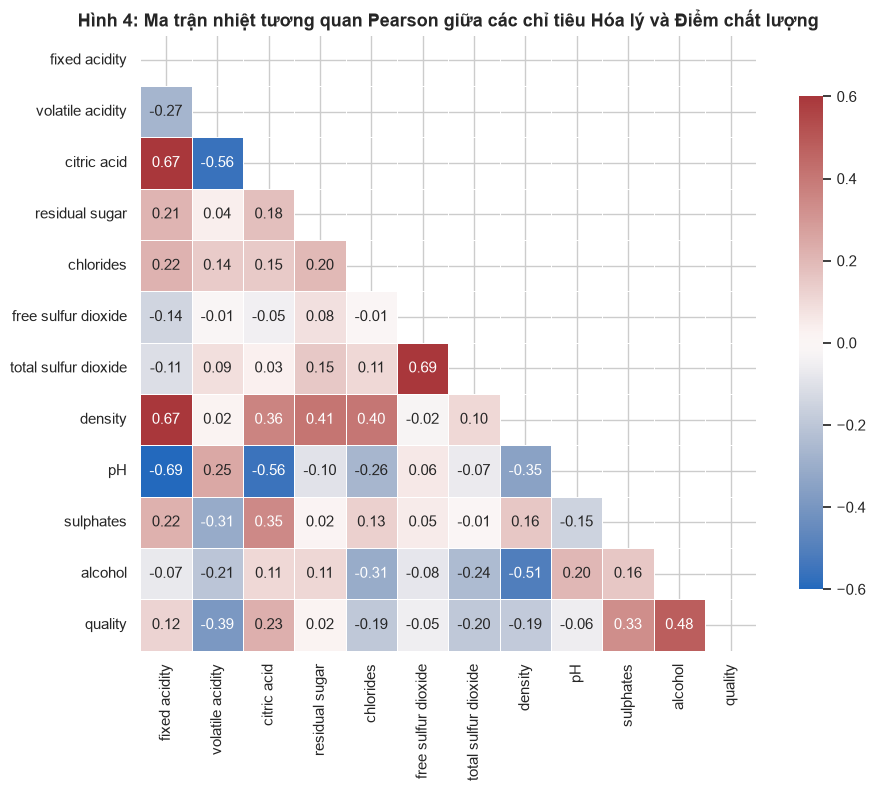

Hệ số phóng đại phương sai (Centered VIF):


,Thuộc tính,Centered VIF
0,fixed acidity,7.2697
1,volatile acidity,1.7703
2,citric acid,2.9577
3,residual sugar,1.8846
4,chlorides,1.3603
5,free sulfur dioxide,2.0467
6,total sulfur dioxide,2.3526
7,density,7.0764
8,pH,3.2324
9,sulphates,1.3342


In [15]:
# 1. Trực quan hóa Heatmap (Figure 4)
raw_cols = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
            'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
            'pH', 'sulphates', 'alcohol', 'quality']

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(df_final[raw_cols].corr(), dtype=bool))
sns.heatmap(df_final[raw_cols].corr(), mask=mask, cmap='vlag', vmin=-0.6, vmax=0.6,
            annot=True, fmt='.2f', square=True, linewidths=.5, cbar_kws={'shrink': .8})
plt.title('Hình 4: Ma trận nhiệt tương quan Pearson giữa các chỉ tiêu Hóa lý và Điểm chất lượng', fontsize=13, fontweight='bold')
plt.show()

# 2. Tính hệ số phóng đại phương sai (Centered VIF)
X_centered = df_final[input_features] - df_final[input_features].mean()
vif_df = pd.DataFrame({
    'Thuộc tính': input_features,
    'Centered VIF': [round(variance_inflation_factor(X_centered.values, i), 4) for i in range(len(input_features))]
})
print("Hệ số phóng đại phương sai (Centered VIF):")
display(vif_df)

#### Biểu đồ 2: Phân phối Violin & Boxplot cho Alcohol và Volatile Acidity (Figure 5)
- **Ghi chú dữ liệu:** Biểu đồ thể hiện dữ liệu sau Winsorization.
- **Thống kê xác thực từ bảng số liệu (Làm tròn 2 chữ số thập phân):**
  - *Nồng độ cồn trung bình:* Nhìn chung cao hơn ở các nhóm có điểm chất lượng cao, mặc dù xu hướng không tăng đơn điệu tại mọi mức điểm: điểm 3 ($9.96\%$), điểm 4 ($10.27\%$), điểm 5 ($9.89\%$), điểm 6 ($10.66\%$), điểm 7 ($11.49\%$) và điểm 8 ($12.10\%$).
  - *Axit dễ bay hơi trung bình:* Nhìn chung có xu hướng giảm khi điểm chất lượng tăng: điểm 3 ($0.81\,g/dm^3$), điểm 4 ($0.69\,g/dm^3$), điểm 5 ($0.58\,g/dm^3$), điểm 6 ($0.50\,g/dm^3$), điểm 7 ($0.40\,g/dm^3$); tuy nhiên nhóm quality 8 ghi nhận mức tăng nhẹ ($0.43\,g/dm^3$) so với nhóm quality 7.

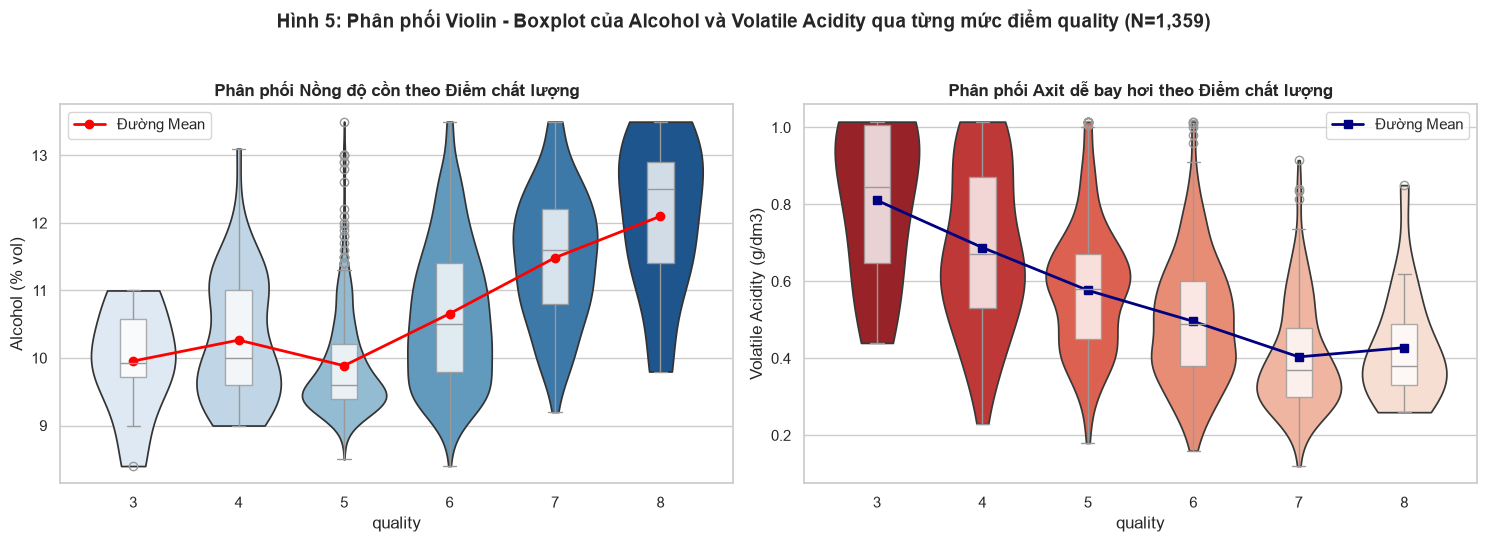

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Nồng độ cồn
sns.violinplot(x='quality', y='alcohol', data=df_final, palette='Blues', inner=None, ax=axes[0], cut=0)
sns.boxplot(x='quality', y='alcohol', data=df_final, width=0.25, ax=axes[0], color='white', boxprops=dict(alpha=0.8))
alc_m = df_final.groupby('quality')['alcohol'].mean()
axes[0].plot(range(len(alc_m)), alc_m.values, marker='o', color='red', linewidth=2, label='Đường Mean')
axes[0].set_title('Phân phối Nồng độ cồn theo Điểm chất lượng', fontweight='bold')
axes[0].set_ylabel('Alcohol (% vol)')
axes[0].legend()

# Axit dễ bay hơi
sns.violinplot(x='quality', y='volatile acidity', data=df_final, palette='Reds_r', inner=None, ax=axes[1], cut=0)
sns.boxplot(x='quality', y='volatile acidity', data=df_final, width=0.25, ax=axes[1], color='white', boxprops=dict(alpha=0.8))
va_m = df_final.groupby('quality')['volatile acidity'].mean()
axes[1].plot(range(len(va_m)), va_m.values, marker='s', color='navy', linewidth=2, label='Đường Mean')
axes[1].set_title('Phân phối Axit dễ bay hơi theo Điểm chất lượng', fontweight='bold')
axes[1].set_ylabel('Volatile Acidity (g/dm3)')
axes[1].legend()

fig.suptitle('Hình 5: Phân phối Violin - Boxplot của Alcohol và Volatile Acidity qua từng mức điểm quality (N=1,359)', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

#### Biểu đồ 3: Phân bố mẫu rượu theo hàm lượng Axit dễ bay hơi và Axit Citric (Figure 6)
- **Lưu ý diễn giải:** Hai đường tham chiếu nét đứt tại $0.50\,g/dm^3$ (Volatile Acidity) và $0.25\,g/dm^3$ (Citric Acid) là **các ngưỡng minh họa do nhóm quan sát trực quan đề xuất** nhằm hỗ trợ quan sát mật độ tập trung mẫu, không phải ranh giới đã qua kiểm định thống kê hay mô hình hóa chứng minh.
- **Chú giải chuẩn xác:** Legend được khởi tạo thông qua `matplotlib.lines.Line2D` để đảm bảo khớp hoàn toàn màu sắc và ký hiệu.

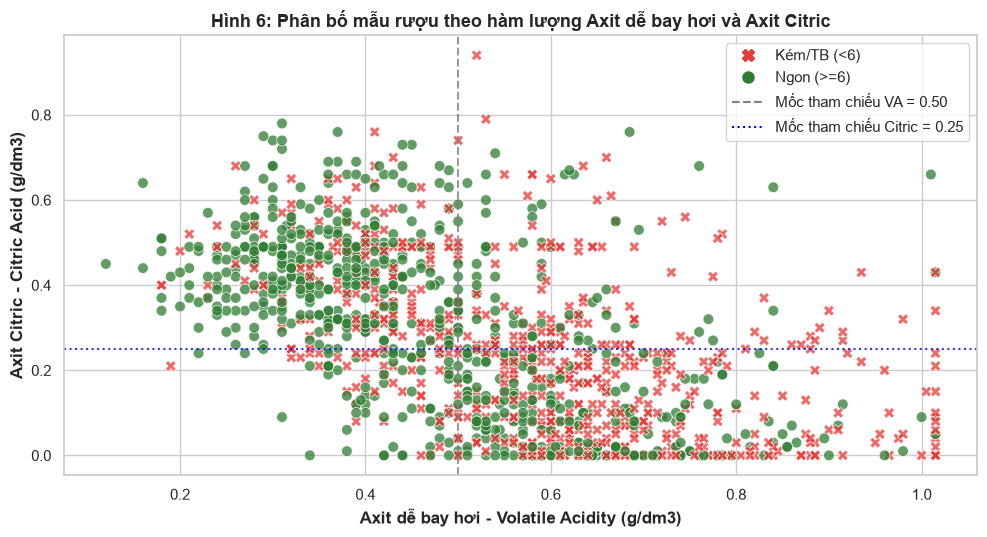

In [17]:
plt.figure(figsize=(10, 5.5))
sns.scatterplot(
    x='volatile acidity', y='citric acid',
    hue='quality_binary', palette={0: '#E53935', 1: '#2E7D32'},
    style='quality_binary', markers=['X', 'o'],
    data=df_final, alpha=0.75, s=60, legend=False
)
plt.axvline(0.5, color='gray', linestyle='--', alpha=0.8)
plt.axhline(0.25, color='blue', linestyle=':', alpha=0.8)

# Custom legend handles
handles = [
    Line2D([0], [0], marker='X', linestyle='None', color='#E53935', markersize=8, label='Kém/TB (<6)'),
    Line2D([0], [0], marker='o', linestyle='None', color='#2E7D32', markersize=8, label='Ngon (>=6)'),
    Line2D([0], [0], color='gray', linestyle='--', label='Mốc tham chiếu VA = 0.50'),
    Line2D([0], [0], color='blue', linestyle=':', label='Mốc tham chiếu Citric = 0.25')
]
plt.legend(handles=handles, loc='upper right', frameon=True)
plt.title('Hình 6: Phân bố mẫu rượu theo hàm lượng Axit dễ bay hơi và Axit Citric', fontsize=13, fontweight='bold')
plt.xlabel('Axit dễ bay hơi - Volatile Acidity (g/dm3)', fontweight='bold')
plt.ylabel('Axit Citric - Citric Acid (g/dm3)', fontweight='bold')
plt.tight_layout()
plt.show()

#### Biểu đồ 4: Hồ sơ đặc trưng hóa lý: So sánh nhóm Quality 3–5 và Quality 7–8 (Figure 7)
- **Đại lượng biểu diễn:** Biểu đồ so sánh giá trị **Median sau chuẩn hóa RobustScaler** giữa hai nhóm: Nhóm Quality 3–5 (N = 640) và Nhóm Quality 7–8 (N = 184).
- **Bảng chênh lệch (Difference) cụ thể được tính toán trực tiếp bên dưới:**


--- BẢNG CHÊNH LỆCH MEDIAN ĐẶC TRƯNG ROBUSTSCALED GIỮA HAI NHÓM ---


,Chỉ số,Nhóm Quality 3-5 (N=640),Nhóm Quality 7-8 (N=184),Chênh lệch (Difference)
0,alcohol,-0.312500,0.875000,1.187500
1,sulphates,-0.222222,0.666667,0.888889
2,citric acid,-0.117647,0.411765,0.529412
3,fixed acidity,-0.047619,0.380952,0.428571
4,volatile acidity,0.280000,-0.600000,-0.880000
5,total sulfur dioxide,0.219512,-0.280488,-0.500000


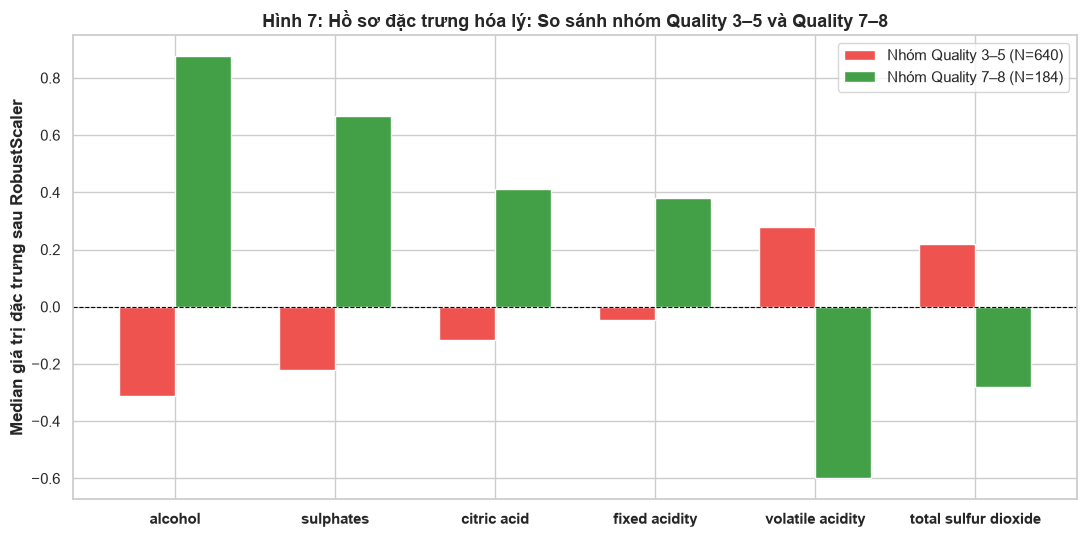

In [18]:
compare_cols = ['alcohol', 'sulphates', 'citric acid', 'fixed acidity', 'volatile acidity', 'total sulfur dioxide']
low_prof = df_final[df_final['quality'] <= 5][[f'{c}_scaled' for c in compare_cols]].median()
high_prof = df_final[df_final['quality'] >= 7][[f'{c}_scaled' for c in compare_cols]].median()
diff = high_prof - low_prof

comp_df = pd.DataFrame({
    'Chỉ số': compare_cols,
    'Nhóm Quality 3-5 (N=640)': low_prof.values,
    'Nhóm Quality 7-8 (N=184)': high_prof.values,
    'Chênh lệch (Difference)': diff.values
})

# In bảng chênh lệch cụ thể
print("\n--- BẢNG CHÊNH LỆCH MEDIAN ĐẶC TRƯNG ROBUSTSCALED GIỮA HAI NHÓM ---")
display(comp_df)

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(compare_cols))
w = 0.35
ax.bar(x - w/2, comp_df['Nhóm Quality 3-5 (N=640)'], w, label='Nhóm Quality 3–5 (N=640)', color='#EF5350')
ax.bar(x + w/2, comp_df['Nhóm Quality 7-8 (N=184)'], w, label='Nhóm Quality 7–8 (N=184)', color='#43A047')
ax.set_ylabel('Median giá trị đặc trưng sau RobustScaler', fontweight='bold')
ax.set_title('Hình 7: Hồ sơ đặc trưng hóa lý: So sánh nhóm Quality 3–5 và Quality 7–8', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(compare_cols, fontweight='bold')
ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

---
# GIAI ĐOẠN 4: ĐÁNH GIÁ TÁC ĐỘNG VÀ KHUYẾN NGHỊ

### 4.1. Tóm tắt các phát hiện chuyên môn nổi bật
1. **Các yếu tố có tương quan mạnh nhất:** Nồng độ cồn (`alcohol`, $r = +0.4827, \rho = +0.4880$) và hàm lượng sunfat (`sulphates`, $r = +0.3306, \rho = +0.3811$) có tương quan thuận có ý nghĩa thống kê với điểm chất lượng cảm quan, trong khi axit dễ bay hơi (`volatile acidity`, $r = -0.3921, \rho = -0.3874$) có mối tương quan nghịch mạnh mẽ nhất.
2. **Vai trò của đường dư:** Cả hai phép kiểm tra tương quan tuyến tính Pearson ($r = +0.0191, p = 0.481$) và tương quan thứ bậc Spearman ($\rho = +0.0249, p = 0.359$) đều chưa tìm thấy bằng chứng thống kê ủng hộ mối liên hệ giữa đường dư (`residual sugar`) và điểm chất lượng vang đỏ trong tập mẫu.
3. **Tác động của phương pháp tiền xử lý:** 
   - Phân tích độ nhạy của bước Deduplication cho thấy việc loại bỏ 240 dòng lặp không làm thay đổi đáng kể các hệ số tương quan của 7 biến được khảo sát ($|\Delta r| \le 0.007245$).
   - Việc áp dụng Winsorization capping giúp kiểm soát biên cực đoan cho các thuật toán học máy nhưng làm tăng nhẹ hệ số tương quan của `sulphates` (từ $0.2488$ lên $0.3306$) và `chlorides` (từ $-0.1310$ lên $-0.1938$), cần được ghi nhận minh bạch trong báo cáo.

---

### 4.2. Đề xuất giải pháp mang tính ứng dụng thực tế
1. **Kiểm soát quy trình lên men (Operations & Brewing):**
   - Theo dõi sát sao nồng độ axit axetic (`volatile acidity`). Trong thực tế sản xuất rượu vang, chỉ số này tăng cao thường liên quan đến hoạt động của vi khuẩn axetic, cần can thiệp kiểm soát nhiệt độ thùng ủ và kiểm soát nồng độ $SO_2$ tự do để hạn chế sự hình thành mùi giấm.
2. **Khuyến nghị xây dựng hệ thống dự báo (Predictive Modeling):**
   - Trong các nghiên cứu dự báo tiếp theo, nhóm đề xuất sử dụng `Pipeline` (ví dụ: `imblearn.pipeline.Pipeline` hoặc `sklearn.pipeline.Pipeline`).
   - Tham số chuẩn hóa (fit scaler) cần được tính toán riêng biệt trên tập huấn luyện (Train set) trong từng fold của Cross-validation để ngăn ngừa rò rỉ dữ liệu (Data Leakage).
   - Bước imputation chỉ bổ sung khi phát sinh missing values (dataset hiện tại 100% đầy đủ); bước encoding chỉ cần thiết khi có thêm các biến định danh/phân loại trong tương lai.

---

### 4.3. Giới hạn dữ liệu và Định hướng mở rộng tương lai
1. **Giới hạn hiện tại:**
   - Dữ liệu thu thập từ một vùng địa lý duy nhất (Vinho Verde, Bồ Đào Nha - Cortez et al., 2009).
   - Tập dữ liệu không chứa các biến số ngoại cảnh quan trọng: Giống nho (Grape variety), Năm mùa vụ (Vintage), Thời gian ủ thùng sồi (Oak aging), hay phân hạng thương mại và giá bán.
   - Biến mục tiêu `quality` bị mất cân bằng lớp ở các mức điểm cực 3 và 8.
2. **Hướng mở rộng:**
   - Thu thập bổ sung các chỉ số khí tượng mùa vụ (lượng mưa, số giờ nắng).
   - Thực nghiệm huấn luyện mô hình dự báo kèm đánh giá đa thước đo (F1-score, ROC-AUC) và ứng dụng kỹ thuật **SHAP** để giải thích đóng góp của từng thuộc tính cho từng mẻ rượu cụ thể.

---

### 4.4. Tài liệu tham khảo (References)
1. Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems*, 47(4), 547–553. https://doi.org/10.1016/j.dss.2009.05.016
2. UCI Machine Learning Repository. (2009). *Wine Quality*. https://doi.org/10.24432/C56S3T
